# 11 — Zbritja e gradientit dhe optimizimi numerik

        **Pyetja udhëheqëse:** Si lëvizim në hapësirën e parametrave drejt një minimumi?

        Ky notebook është ndërtuar si një mësim i plotë kompjuterik. Rruga kryesore ndjek:
        **problem konkret → model matematikor → zbatim nga parimet e para → bibliotekë profesionale → krahasim → interpretim**.

        ## Objektivat
        - Të interpretohet gradienti gjeometrikisht.
- Të implementohet gradient descent.
- Të studiohet roli i learning rate.
- Të prezantohet zbritja stokastike e gradientit.

        > **Rruga bazë për orën mësimore (45–60 min)** shënohet me seksionet **CORE**.  
        > Seksionet **EXTENDED** dhe **PLAYGROUND** janë për thellim dhe punë të pavarur.

## Pse kjo temë është e nevojshme?

Shumë algoritme të nxënies automatike janë, në thelb, probleme optimizimi. Nëse kuptojmë si lëvizim në një sipërfaqe humbjeje dhe pse një hap i madh mund të destabilizojë iteracionin, kemi një bazë të fortë për të kuptuar trajnimin e modeleve më të ndërlikuara.

Do të lidhim derivatin me një trajektore numerike konkrete, do të shohim rolin e learning rate dhe do të dallojmë gradient descent të plotë nga varianti stokastik.

### Si duhet lexuar ky notebook

Për çdo bllok kodi do të shpjegojmë **pse** kryhet ai hap, çfarë pyetjeje i përgjigjet dhe çfarë duhet të kontrollojmë në dalje. Kodi nuk trajtohet si recetë: çdo grafik dhe çdo metrikë duhet të rikthehet te hipoteza matematikore dhe te interpretimi fizik. Kur një rezultat nuk sillet siç presim, pyetja e parë nuk është “si ta rrisim score-in?”, por “cilën hipotezë të modelit ose të të dhënave po shkelim?”.

### Para se të ekzekutojmë: Mjedisi llogaritës dhe riprodhueshmëria

Ngarkojmë bibliotekat që do të përdoren dhe fiksojmë `RANDOM_STATE = 42`. Ky seed nuk e bën problemin determinist në kuptimin fizik; ai thjesht na lejon të përsërisim të njëjtin eksperiment llogaritës dhe të diskutojmë metodën pa u hutuar nga ndryshime të rastësishme të mostrës.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [1]:
# Qëllimi i këtij blloku: Mjedisi llogaritës dhe riprodhueshmëria.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import numpy as np
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import pandas as pd
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import matplotlib.pyplot as plt
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from pathlib import Path
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import time

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# Përditësojmë parametrat në drejtimin e kundërt të gradientit për të ulur humbjen.
print("11 — Zbritja e gradientit dhe optimizimi numerik")
print("Seed:", RANDOM_STATE)

11 — Zbritja e gradientit dhe optimizimi numerik
Seed: 42


**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 1. Një sipërfaqe humbjeje — CORE

Zbritja e gradientit (gradient descent) përdor
$$
\theta_{n+1}=\theta_n-\eta\nabla L(\theta_n).
$$
Gradienti tregon drejtimin e rritjes më të shpejtë; prandaj $-\nabla L$ tregon drejtimin lokal të
zbritjes më të shpejtë.

### Para se të ekzekutojmë: Një sipërfaqe ku mund ta shohim gradientin

Zgjedhim një funksion kuadratik dy-dimensional sepse minimumi dhe gradienti njihen analitikisht. Konturet na lejojnë të interpretojmë çdo hap si lëvizje në hapësirën e parametrave.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

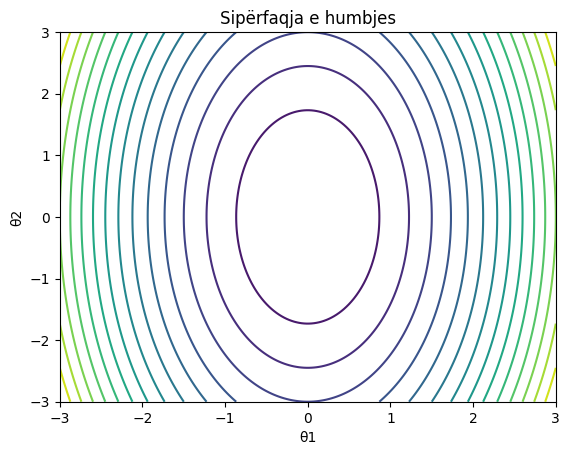

In [2]:
# Qëllimi i këtij blloku: Një sipërfaqe ku mund ta shohim gradientin.
def loss(th):
    x,y=th
    return 0.5*(4*x*x + y*y)
def grad(th):
    x,y=th
    return np.array([4*x,y])

xx,yy=np.meshgrid(np.linspace(-3,3,200),np.linspace(-3,3,200))
zz=0.5*(4*xx**2+yy**2)
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.contour(xx,yy,zz,levels=20)
ax.set_xlabel("θ1"); ax.set_ylabel("θ2"); ax.set_title("Sipërfaqja e humbjes")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 2. Trajektorja e optimizimit — CORE

### Para se të ekzekutojmë: Implementimi i algoritmit iterativ

Ruajmë të gjithë historinë e parametrave, jo vetëm minimumin final. Kjo është e rëndësishme sepse konvergjenca është proces dinamik dhe mund të dështojë edhe kur formula e update-it është e saktë.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

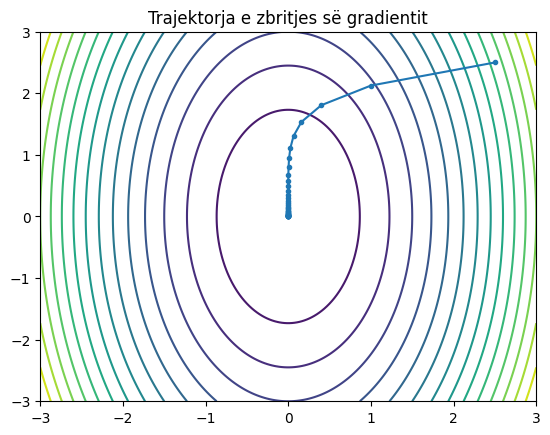

In [3]:
# Qëllimi i këtij blloku: Implementimi i algoritmit iterativ.
def gd(theta0,eta,n=50):
    th=np.array(theta0,dtype=float); hist=[th.copy()]
    # Përsërisim procedurën për të studiuar konvergjencën ose ndjeshmërinë ndaj parametrave.
    for _ in range(n):
        th=th-eta*grad(th); hist.append(th.copy())
    return np.array(hist)

hist=gd([2.5,2.5],0.15,40)
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.contour(xx,yy,zz,levels=20)
ax.plot(hist[:,0],hist[:,1],marker="o",markersize=3)
# Përditësojmë parametrat në drejtimin e kundërt të gradientit për të ulur humbjen.
ax.set_title("Trajektorja e zbritjes së gradientit")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

### Optimizer-i i ripërdorshëm nga `src/`

### Para se të ekzekutojmë: Kontroll me optimizer-in e `src`

Përdorim funksionin e ripërdorshëm për të verifikuar se implementimi i paketizuar ndjek të njëjtën trajektore konceptuale.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [4]:
# Qëllimi i këtij blloku: Kontroll me optimizer-in e `src`.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import sys
# Kërkojmë automatikisht rrënjën e repository-t, në mënyrë që notebook-u të funksionojë nga dosje të ndryshme.
ROOT = Path.cwd()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "src").is_dir():
        sys.path.insert(0, str(candidate))
        break
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from src.optimization.gradient_descent import gradient_descent
# Përditësojmë parametrat në drejtimin e kundërt të gradientit për të ulur humbjen.
theta_src, hist_src = gradient_descent([2.5,2.5], grad, lr=0.15, n_iter=40)
print("Minimumi nga src:", theta_src)

Minimumi nga src: [3.02231455e-16 3.75575312e-03]


**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 3. Learning rate — CORE

### Para se të ekzekutojmë: Learning rate dhe stabiliteti

Tre vlera të $\eta$ tregojnë tre regjime: konvergjencë e ngadaltë, konvergjencë e mirë dhe paqëndrueshmëri. Learning rate nuk është detaj teknik; ai përcakton dinamikën numerike të algoritmit.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

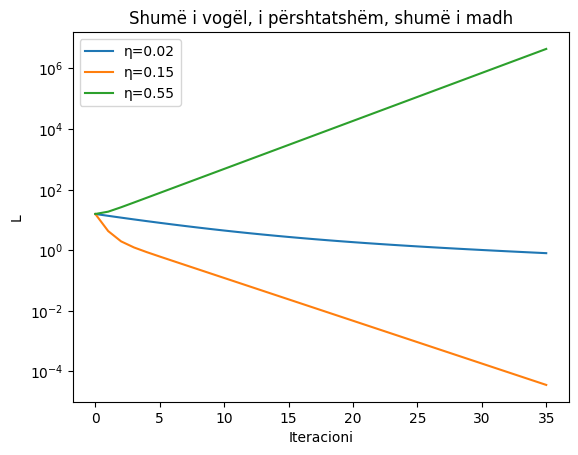

In [5]:
# Qëllimi i këtij blloku: Learning rate dhe stabiliteti.
etas=[0.02,0.15,0.55]
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
for eta in etas:
    h=gd([2.5,2.5],eta,35)
    vals=[loss(t) for t in h]
    ax.semilogy(vals,label=f"η={eta}")
ax.set_xlabel("Iteracioni"); ax.set_ylabel("L")
ax.legend(); ax.set_title("Shumë i vogël, i përshtatshëm, shumë i madh")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 4. Regresion linear me gradient descent — CORE

### Para se të ekzekutojmë: Regresioni si problem optimizimi

Rikthehemi te regresioni linear, por këtë herë nuk përdorim zgjidhjen analitike. Minimizojmë MSE me gradient descent për të treguar se i njëjti model mund të trajnohet me metoda të ndryshme numerike.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [6]:
# Qëllimi i këtij blloku: Regresioni si problem optimizimi.
x=np.linspace(-2,2,120)
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
y=1.8*x+0.6+rng.normal(0,0.35,len(x))
A=np.c_[np.ones(len(x)),x]
theta=np.zeros(2); eta=0.08; hist=[]
# Përsërisim procedurën për të studiuar konvergjencën ose ndjeshmërinë ndaj parametrave.
for _ in range(250):
    pred=A@theta
    g=2*A.T@(pred-y)/len(y)
    theta-=eta*g
    hist.append(theta.copy())
theta

array([0.57885934, 1.77041075])

### Para se të ekzekutojmë: Kontrolli i rezultatit në hapësirën e të dhënave

Pas optimizimit e kthejmë vëmendjen te problemi fizik/statistikor: a përshkruan vija të dhënat në mënyrë të arsyeshme? Konvergjenca e humbjes nuk garanton model të përshtatshëm.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

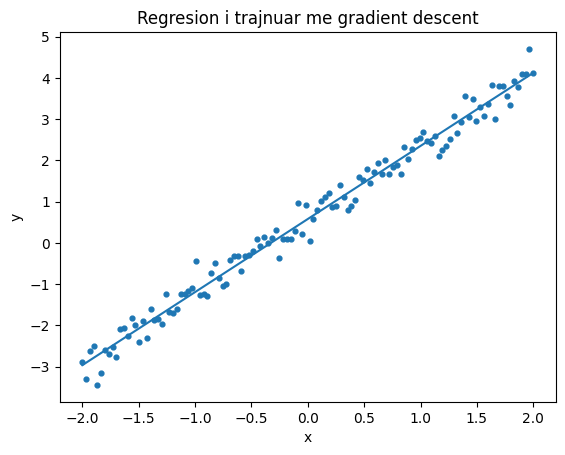

In [7]:
# Qëllimi i këtij blloku: Kontrolli i rezultatit në hapësirën e të dhënave.
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.scatter(x,y,s=12)
ax.plot(x,A@theta)
ax.set_xlabel("x"); ax.set_ylabel("y")
# Përditësojmë parametrat në drejtimin e kundërt të gradientit për të ulur humbjen.
ax.set_title("Regresion i trajnuar me gradient descent")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 5. Trajektorja e parametrave — CORE

### Para se të ekzekutojmë: Trajektorja në hapësirën e parametrave

Grafiku $(\beta_0,\beta_1)$ tregon si ndryshon njëkohësisht intercept-i dhe pjerrësia. Kjo është ura ndërmjet një algoritmi iterativ dhe gjeometrisë së funksionit objektiv.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

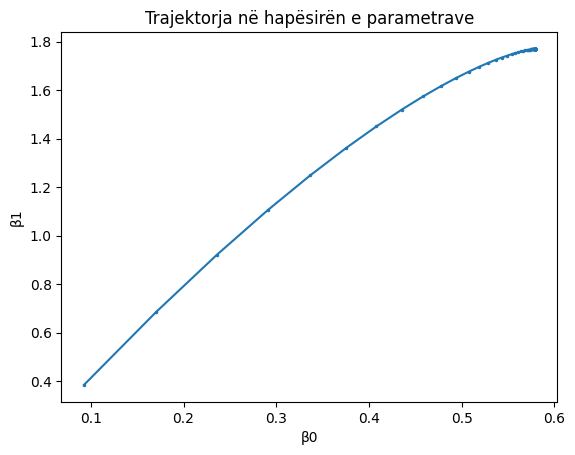

In [8]:
# Qëllimi i këtij blloku: Trajektorja në hapësirën e parametrave.
H=np.array(hist)
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.plot(H[:,0],H[:,1],marker=".",markersize=3)
ax.set_xlabel("β0"); ax.set_ylabel("β1")
ax.set_title("Trajektorja në hapësirën e parametrave")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

---
## Deri këtu: materiali bazë për orën mësimore

Në një seancë rreth 60 minuta, zakonisht ndalemi këtu. Seksionet që vijojnë janë për thellim,
ushtrime të pavarura dhe eksperimentim.

# 6. Zbritja stokastike e gradientit — EXTENDED

Në zbritjen stokastike të gradientit (stochastic gradient descent, SGD), gradienti vlerësohet nga
një mostër ose mini-batch. Kjo ul koston për hap dhe fut stokasticitet në trajektore.

### Para se të ekzekutojmë: Zbritja stokastike e gradientit

Në SGD përdorim mostra individuale, prandaj trajektorja bëhet më e zhurmshme. Ky stokasticitet mund të përshpejtojë përparimin në dataset-e të mëdha, por kërkon kontroll më të kujdesshëm të learning rate.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

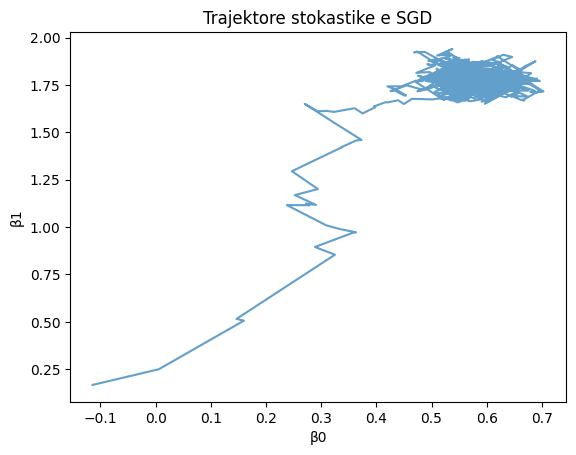

In [9]:
# Qëllimi i këtij blloku: Zbritja stokastike e gradientit.
theta=np.zeros(2); eta=0.03; path=[]
# Përsërisim procedurën për të studiuar konvergjencën ose ndjeshmërinë ndaj parametrave.
for epoch in range(12):
    for i in rng.permutation(len(x)):
        ai=A[i]
        err=ai@theta-y[i]
        theta-=eta*2*err*ai
        path.append(theta.copy())
P=np.array(path)
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.plot(P[:,0],P[:,1],alpha=0.7)
ax.set_xlabel("β0"); ax.set_ylabel("β1")
ax.set_title("Trajektore stokastike e SGD")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 7. Aplikim jo-fizik: optimizim i një modeli ekonomik — EXTENDED

E njëjta logjikë numerike përdoret në optimizimin e modeleve në ekonomi, biologji dhe inxhinieri. Diferenca kryesore është kuptimi i funksionit të humbjes, jo algoritmi i optimizimit.

# Ushtrime — PLAYGROUND

        ## A. Ushtrime të shkurtra
        1. Gjeni teorikisht kufirin e stabilitetit për η në funksionin kuadratik të dhënë.
2. Krahasoni numrin e iteracioneve për η të ndryshme.
3. Implementoni early stopping kur norma e gradientit bie nën një prag.
4. Krahasoni batch GD me SGD.

        ## B. Ushtrim i plotë
        Trajnoni regresionin logjistik me gradient descent dhe vizualizoni humbjen për tre learning rates.

        ## C. Playground
        Ndryshoni learning rate, pikën fillestare, batch size dhe numrin e iteracioneve.

In [10]:
# TODO / PLAYGROUND
# Ndryshoni parametrat, shtoni grafikë ose krahasoni modele të tjera.

## Përmbledhje konceptuale e kapitullit

Notebook-u **Zbritja e gradientit dhe optimizimi numerik** duhet të lihet me një ide të qartë: algoritmi është vetëm një hallkë e arsyetimit. Para tij kemi zgjedhjen e përfaqësimit dhe hipotezat mbi të dhënat; pas tij kemi validimin, diagnostikën dhe interpretimin. Nëse një student mund të ekzekutojë të gjitha qelizat por nuk mund të shpjegojë pse secila prej tyre është e nevojshme, atëherë puna llogaritëse nuk është përfunduar ende.

Për studim të mëtejshëm, rikthehuni te shënimet e leksionit për derivimet e plota dhe përdoreni këtë notebook si laborator ku këto ide testohen numerikisht.

### Zgjidhje orientuese për instruktorin
- Për një funksion kuadratik stabiliteti lidhet me eigenvalue-in maksimal të Hessian-it; learning rate tepër i madh shkakton oscilim/divergjencë.
- Early stopping mund të përdorë normën e gradientit ose ndryshimin e humbjes.
- SGD ka trajektore më të zhurmshme por hapa më të lirë.